# Stage 3.1 — Train/Test Split & Train-only EDA

## Objective and scope

This Notebook creates the project's deterministic 80/20 Train / Holdout Test split and then performs the authorized EDA on Train only. It is a learning artifact: each formal figure states its question, purpose, observed evidence, and an open Stage 3.2 question.

## Test-isolation contract

The full raw dataset is used before splitting only for non-target-aware structure and integrity checks. The target is used to stratify the split. Immediately afterward, Test is used only for row-count, schema, ID-overlap, full-coverage, and reproducibility assertions; the Test frame is then deleted from the live analysis state. Every target-aware table and figure below uses `train_df` or its EDA-only display copy.

This Notebook does not create train/test CSV files, predictors, model pipelines, WOE, bins, samples, models, or model evaluation. It does not execute the Luca reference Notebook.


In [1]:
from pathlib import Path
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

TARGET = "default.payment.next.month"
ID_COL = "ID"
RANDOM_STATE = 42
TEST_SIZE = 0.20
PAY_SOURCE_ORDER = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
PAY_CHRONO = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_0"]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]
EXPECTED_FIGURE_IDS = [f"EDA-{i:02d}" for i in range(1, 14)]
figure_registry = []

def locate_project_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data/raw/UCI_Credit_Card.csv").is_file():
            return candidate
    raise FileNotFoundError("Could not locate data/raw/UCI_Credit_Card.csv from the launch directory or its parents.")

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def stable_id_set_hash(values):
    canonical = "\n".join(str(int(value)) for value in sorted(values))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

def finalize_figure(fig, figure_id, title):
    assert figure_id in EXPECTED_FIGURE_IDS
    assert figure_id not in figure_registry
    figure_registry.append(figure_id)
    fig.suptitle(f"{figure_id} — {title}", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    plt.close(fig)

project_root = locate_project_root()
data_path = project_root / "data/raw/UCI_Credit_Card.csv"

print("Stage 3.1 execution environment")
print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Launch directory:", Path.cwd().resolve())
print("Project root:", project_root)
print("Raw CSV:", data_path)


Matplotlib is building the font cache; this may take a moment.


Stage 3.1 execution environment
Python executable: /Users/yu/2.工作/Risk Analysis Project/.venv/bin/python
Python version: 3.9.6
Launch directory: /Users/yu/2.工作/Risk Analysis Project
Project root: /Users/yu/2.工作/Risk Analysis Project
Raw CSV: /Users/yu/2.工作/Risk Analysis Project/data/raw/UCI_Credit_Card.csv


## 1. Raw-data integrity check — full raw data, non-target-aware only

The checks in this section confirm that the formal input has not drifted since Stage 2. They inspect structure, allowed target values, and raw predictor behavior. They deliberately do **not** compute full-data default rates, target relationships, target correlations, or target-driven bins.


In [2]:
raw_df = pd.read_csv(data_path)

raw_structure = pd.DataFrame({
    "value": [
        raw_df.shape[0], raw_df.shape[1], int(raw_df.isna().sum().sum()),
        int(raw_df.duplicated().sum()), int(raw_df[ID_COL].nunique()),
        int(raw_df[ID_COL].duplicated().sum()),
        int((~np.isfinite(raw_df.select_dtypes(include=np.number).to_numpy())).sum()),
        sorted(raw_df[TARGET].dropna().unique().tolist()), data_path.stat().st_size,
        sha256_file(data_path),
    ]
}, index=[
    "row_count", "column_count", "total_missing_cells", "exact_duplicate_rows",
    "unique_ID_count", "duplicate_ID_rows", "non_finite_numeric_cells",
    "target_value_set_only", "raw_file_bytes", "raw_file_SHA256",
])

demographic_structure = pd.DataFrame({
    "actual_codes_or_range": [
        sorted(raw_df["SEX"].unique().tolist()),
        sorted(raw_df["EDUCATION"].unique().tolist()),
        sorted(raw_df["MARRIAGE"].unique().tolist()),
        (int(raw_df["AGE"].min()), int(raw_df["AGE"].max())),
        (float(raw_df["LIMIT_BAL"].min()), float(raw_df["LIMIT_BAL"].max())),
    ]
}, index=["SEX", "EDUCATION", "MARRIAGE", "AGE", "LIMIT_BAL"])

pay_code_sets = pd.DataFrame({
    "raw_code_set": [sorted(raw_df[col].unique().tolist()) for col in PAY_SOURCE_ORDER]
}, index=PAY_SOURCE_ORDER)

amount_integrity = pd.DataFrame({
    "zero_count": [(raw_df[col] == 0).sum() for col in BILL_COLS + PAY_AMT_COLS],
    "negative_count": [(raw_df[col] < 0).sum() for col in BILL_COLS + PAY_AMT_COLS],
    "min": [raw_df[col].min() for col in BILL_COLS + PAY_AMT_COLS],
    "p99": [raw_df[col].quantile(0.99) for col in BILL_COLS + PAY_AMT_COLS],
    "max": [raw_df[col].max() for col in BILL_COLS + PAY_AMT_COLS],
}, index=BILL_COLS + PAY_AMT_COLS)

assert raw_df.shape == (30000, 25)
assert raw_df.columns.tolist() == [
    "ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6", TARGET,
]
assert raw_df.isna().sum().sum() == 0
assert raw_df.duplicated().sum() == 0
assert raw_df[ID_COL].is_unique
assert set(raw_df[TARGET].unique()) == {0, 1}
assert np.isfinite(raw_df.select_dtypes(include=np.number).to_numpy()).all()

print("Full raw-data checks are structural/non-target-aware; no full-data target relationships were computed.")
print("Columns in source order:")
print(raw_df.columns.tolist())
display(raw_structure)
display(raw_df.dtypes.rename("dtype").to_frame())
display(demographic_structure)
display(pay_code_sets)
display(amount_integrity)


Full raw-data checks are structural/non-target-aware; no full-data target relationships were computed.
Columns in source order:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


,value
row_count,30000
column_count,25
total_missing_cells,0
exact_duplicate_rows,0
unique_ID_count,30000
duplicate_ID_rows,0
non_finite_numeric_cells,0
target_value_set_only,"[0, 1]"
raw_file_bytes,2862995
raw_file_SHA256,a0f0ab49d6326671d6cd83be5c88dcf18007025fe9a53e...


,dtype
ID,int64
LIMIT_BAL,float64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64


,actual_codes_or_range
SEX,"[1, 2]"
EDUCATION,"[0, 1, 2, 3, 4, 5, 6]"
MARRIAGE,"[0, 1, 2, 3]"
AGE,"(21, 79)"
LIMIT_BAL,"(10000.0, 1000000.0)"


,raw_code_set
PAY_0,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
PAY_2,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
PAY_3,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
PAY_4,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
PAY_5,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]"
PAY_6,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]"


,zero_count,negative_count,min,p99,max
BILL_AMT1,2008,590,-165580.0,350110.68,964511.0
BILL_AMT2,2506,669,-69777.0,337495.28,983931.0
BILL_AMT3,2870,655,-157264.0,325030.39,1664089.0
BILL_AMT4,3195,675,-170000.0,304997.27,891586.0
BILL_AMT5,3506,655,-81334.0,285868.33,927171.0
BILL_AMT6,4020,688,-339603.0,279505.06,961664.0
PAY_AMT1,5249,0,0.0,66522.18,873552.0
PAY_AMT2,5396,0,0.0,76651.02,1684259.0
PAY_AMT3,5968,0,0.0,70000.00,896040.0
PAY_AMT4,6408,0,0.0,67054.44,621000.0


## 2. Deterministic Train / Holdout Test split

The formal split uses `train_test_split` with Train = 80%, Holdout Test = 20%, `random_state=42`, and `stratify=y`. ID-set hashes use the following canonicalization: convert each ID to its canonical decimal integer string, sort numerically, join with a single newline, add no trailing newline, encode as UTF-8, then calculate SHA-256.

Only technical split-integrity evidence is emitted for Test. Its target distribution and target relationships are neither calculated nor displayed.


In [3]:
train_df, sealed_test_df = train_test_split(
    raw_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=raw_df[TARGET],
)

train_ids = set(train_df[ID_COL].astype(int).tolist())
test_ids = set(sealed_test_df[ID_COL].astype(int).tolist())
full_ids = set(raw_df[ID_COL].astype(int).tolist())
train_id_hash = stable_id_set_hash(train_ids)
test_id_hash = stable_id_set_hash(test_ids)

assert len(train_df) == 24000
assert len(sealed_test_df) == 6000
assert train_df.columns.tolist() == sealed_test_df.columns.tolist() == raw_df.columns.tolist()
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == full_ids
assert len(train_ids) + len(test_ids) == len(full_ids)

replay_train_ids, replay_test_ids = train_test_split(
    raw_df[ID_COL],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=raw_df[TARGET],
)
assert set(replay_train_ids.astype(int)) == train_ids
assert set(replay_test_ids.astype(int)) == test_ids
assert stable_id_set_hash(replay_train_ids) == train_id_hash
assert stable_id_set_hash(replay_test_ids) == test_id_hash

split_evidence = pd.DataFrame({
    "value": [
        "sklearn.model_selection.train_test_split", "80% / 20%", RANDOM_STATE, TARGET,
        len(train_df), len(sealed_test_df), True, True, True,
        train_id_hash, test_id_hash,
        "numeric sort → decimal strings → newline join → no trailing newline → UTF-8 → SHA-256",
    ]
}, index=[
    "method", "train_test_ratio", "random_state", "stratification_target",
    "train_row_count", "test_row_count", "ID_overlap_is_zero",
    "ID_union_covers_raw", "deterministic_replay_matches",
    "train_ID_set_SHA256", "test_ID_set_SHA256", "ID_hash_canonicalization",
])
display(split_evidence)
print("Train ID-set SHA-256:", train_id_hash)
print("Test ID-set SHA-256:", test_id_hash)

# Seal Test and remove full data from the analysis state before target-aware EDA.
del sealed_test_df, replay_train_ids, replay_test_ids, raw_df
TEST_ISOLATION_STATUS = "sealed after technical assertions; Test frame and full raw frame removed from EDA state"
print("Test isolation:", TEST_ISOLATION_STATUS)
print("All subsequent target-aware analysis uses Train only.")


,value
method,sklearn.model_selection.train_test_split
train_test_ratio,80% / 20%
random_state,42
stratification_target,default.payment.next.month
train_row_count,24000
test_row_count,6000
ID_overlap_is_zero,True
ID_union_covers_raw,True
deterministic_replay_matches,True
train_ID_set_SHA256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...


Train ID-set SHA-256: bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857
Test ID-set SHA-256: d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f
Test isolation: sealed after technical assertions; Test frame and full raw frame removed from EDA state
All subsequent target-aware analysis uses Train only.


## 3. EDA-only category views on Train

These mappings exist only to make Train EDA readable; they are not saved predictors or a preprocessing pipeline.

- EDUCATION: 1 → Graduate School; 2 → University; 3 → High School; 0/4/5/6 → Other / Unknown. Official code 4 is “Others”; the exact official meanings of 0/5/6 are unconfirmed, so grouping does not claim semantic identity.
- MARRIAGE: 1 → Married; 2 → Single; 0/3 → Other / Unknown. The exact official meaning of code 0 is unconfirmed.
- SEX labels use the project-verified UCI definition: 1 → Male; 2 → Female.
- AGE remains continuous. No age bin is created.


In [4]:
analysis_train = train_df.copy()
analysis_train["SEX_VIEW"] = analysis_train["SEX"].map({1: "Male", 2: "Female"})
analysis_train["EDUCATION_VIEW"] = analysis_train["EDUCATION"].map({
    1: "Graduate School", 2: "University", 3: "High School",
    0: "Other / Unknown", 4: "Other / Unknown", 5: "Other / Unknown", 6: "Other / Unknown",
})
analysis_train["MARRIAGE_VIEW"] = analysis_train["MARRIAGE"].map({
    1: "Married", 2: "Single", 0: "Other / Unknown", 3: "Other / Unknown",
})

SEX_ORDER = ["Male", "Female"]
EDUCATION_ORDER = ["Graduate School", "University", "High School", "Other / Unknown"]
MARRIAGE_ORDER = ["Married", "Single", "Other / Unknown"]

assert analysis_train[["SEX_VIEW", "EDUCATION_VIEW", "MARRIAGE_VIEW"]].notna().all().all()
assert analysis_train["AGE"].equals(train_df["AGE"])
assert analysis_train[PAY_SOURCE_ORDER].equals(train_df[PAY_SOURCE_ORDER])
print("EDA-only view columns:", ["SEX_VIEW", "EDUCATION_VIEW", "MARRIAGE_VIEW"])
print("AGE remains continuous; PAY raw codes are unchanged.")


EDA-only view columns: ['SEX_VIEW', 'EDUCATION_VIEW', 'MARRIAGE_VIEW']
AGE remains continuous; PAY raw codes are unchanged.


## EDA-01 — Train Target Distribution

### Question

What are the default and non-default counts and proportions in the development sample?

### Why

The bars show Train row counts by the binary target; annotations show within-Train proportions. This establishes the class context without inspecting Test.

### Observed finding

Train contains 18,691 non-default observations (77.8792%) and 5,309 default observations (22.1208%). The positive class is therefore the minority in the development sample.

### Stage 3.2 question

How should later validation metrics and decision criteria reflect the observed Train class imbalance?


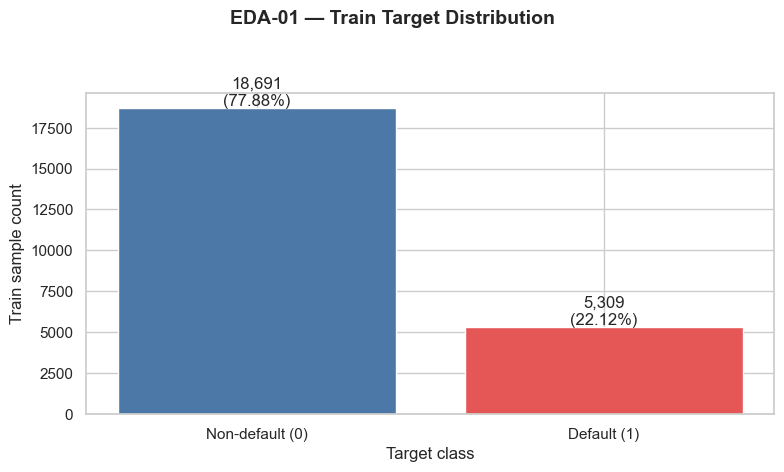

,sample_count,proportion
Non-default (0),18691,0.778792
Default (1),5309,0.221208


In [5]:
target_summary = train_df[TARGET].value_counts().sort_index().rename("sample_count").to_frame()
target_summary["proportion"] = target_summary["sample_count"] / len(train_df)
target_summary.index = ["Non-default (0)", "Default (1)"]

fig, ax = plt.subplots(figsize=(8, 4.8))
colors = ["#4C78A8", "#E45756"]
bars = ax.bar(target_summary.index, target_summary["sample_count"], color=colors)
ax.set_ylabel("Train sample count")
ax.set_xlabel("Target class")
for bar, proportion in zip(bars, target_summary["proportion"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{int(bar.get_height()):,}\n({proportion:.2%})", ha="center", va="bottom")
finalize_figure(fig, "EDA-01", "Train Target Distribution")
display(target_summary)


## EDA-02 — SEX Distribution and Default Rate

### Question

How large are the Train groups for SEX, and how do their observed default rates differ?

### Why

The left panel shows sample counts; the right shows Train default rate. Both use the verified UCI labels, and neither implies causality.

### Observed finding

Train contains 9,486 Male and 14,514 Female observations. The observed default rate is 24.3728% for Male versus 20.6490% for Female, a descriptive gap of 3.72 percentage points.

### Stage 3.2 question

Should SEX be retained, constrained, or separately reviewed in Stage 3.2 given predictive, fairness, and interpretability considerations?


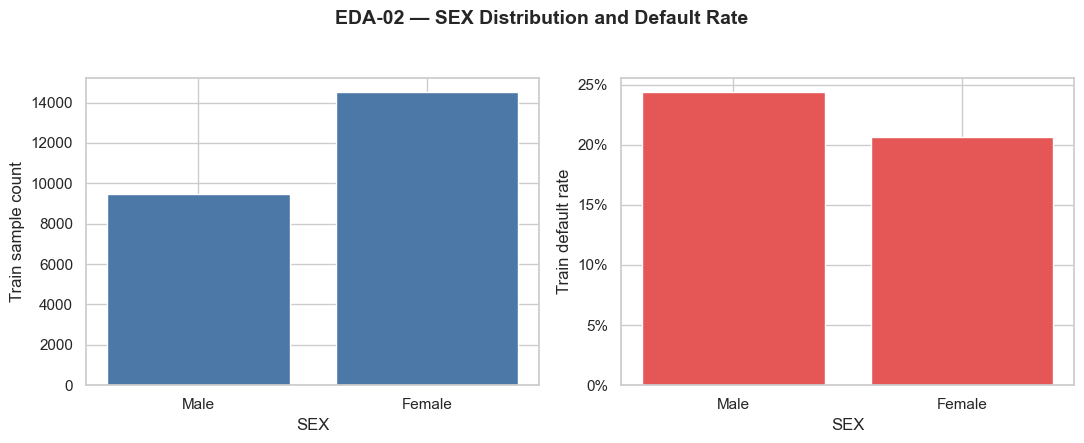

,sample_count,defaults,default_rate
SEX_VIEW,,,
Male,9486,2312,0.243728
Female,14514,2997,0.206490


In [6]:
sex_stats = analysis_train.groupby("SEX_VIEW", observed=True)[TARGET].agg(sample_count="size", defaults="sum", default_rate="mean").reindex(SEX_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(sex_stats.index, sex_stats["sample_count"], color="#4C78A8")
axes[0].set_ylabel("Train sample count"); axes[0].set_xlabel("SEX")
axes[1].bar(sex_stats.index, sex_stats["default_rate"], color="#E45756")
axes[1].set_ylabel("Train default rate"); axes[1].set_xlabel("SEX"); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
for ax in axes: ax.tick_params(axis="x", rotation=0)
finalize_figure(fig, "EDA-02", "SEX Distribution and Default Rate")
display(sex_stats)


## EDA-03 — EDUCATION Distribution and Default Rate

### Question

How are the authorized EDA-only education groups represented in Train, and what default rates are observed?

### Why

Counts reveal group support; rates describe Train outcomes. The grouped Other / Unknown view combines documented code 4 with undocumented 0/5/6 only for EDA readability.

### Observed finding

Graduate School, University, High School, and Other / Unknown contain 8,455, 11,256, 3,903, and 386 Train observations. Their default rates are 19.2904%, 23.7562%, 25.0064%, and 7.2539%; the last rate belongs to a small pooled group and should not be read as a verified business-category effect.

### Stage 3.2 question

Should Stage 3.2 preserve raw education codes, use an explicit unknown grouping, or evaluate another transparent treatment?


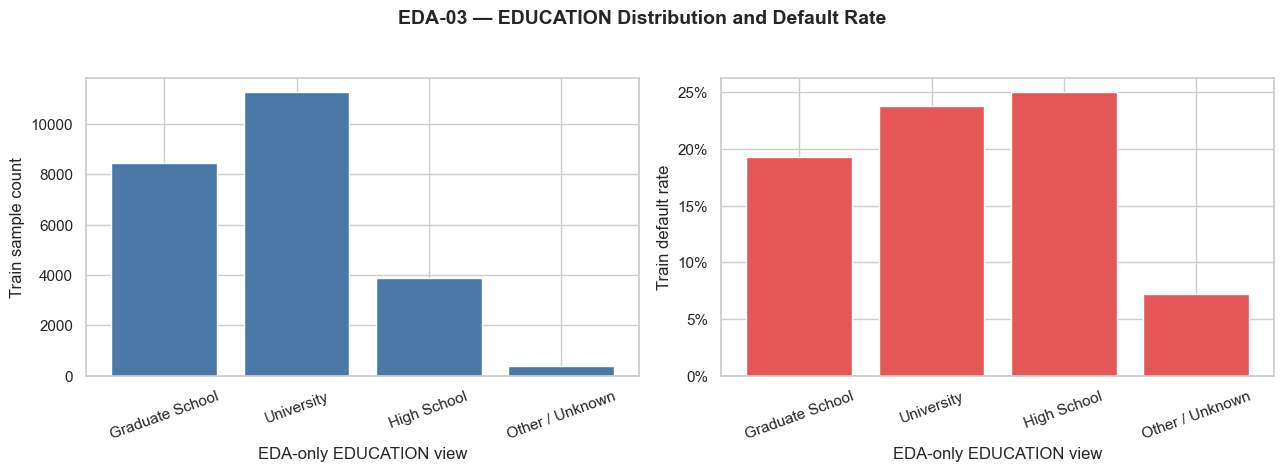

,sample_count,defaults,default_rate
EDUCATION_VIEW,,,
Graduate School,8455,1631,0.192904
University,11256,2674,0.237562
High School,3903,976,0.250064
Other / Unknown,386,28,0.072539


In [7]:
education_stats = analysis_train.groupby("EDUCATION_VIEW", observed=True)[TARGET].agg(sample_count="size", defaults="sum", default_rate="mean").reindex(EDUCATION_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(education_stats.index, education_stats["sample_count"], color="#4C78A8")
axes[0].set_ylabel("Train sample count"); axes[0].set_xlabel("EDA-only EDUCATION view")
axes[1].bar(education_stats.index, education_stats["default_rate"], color="#E45756")
axes[1].set_ylabel("Train default rate"); axes[1].set_xlabel("EDA-only EDUCATION view"); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
for ax in axes: ax.tick_params(axis="x", rotation=20)
finalize_figure(fig, "EDA-03", "EDUCATION Distribution and Default Rate")
display(education_stats)


## EDA-04 — MARRIAGE Distribution and Default Rate

### Question

How are the authorized EDA-only marriage groups represented in Train, and what default rates are observed?

### Why

Counts show support and rates show Train outcomes. Other / Unknown combines raw 0 and 3 for display without asserting that code 0 officially means Other.

### Observed finding

Married, Single, and Other / Unknown contain 10,892, 12,806, and 302 Train observations, with default rates of 23.3015%, 21.0370%, and 25.4967%. The pooled Other / Unknown group is much smaller than the two principal groups.

### Stage 3.2 question

Should Stage 3.2 retain raw marriage codes or use a documented grouping that keeps uncertainty visible?


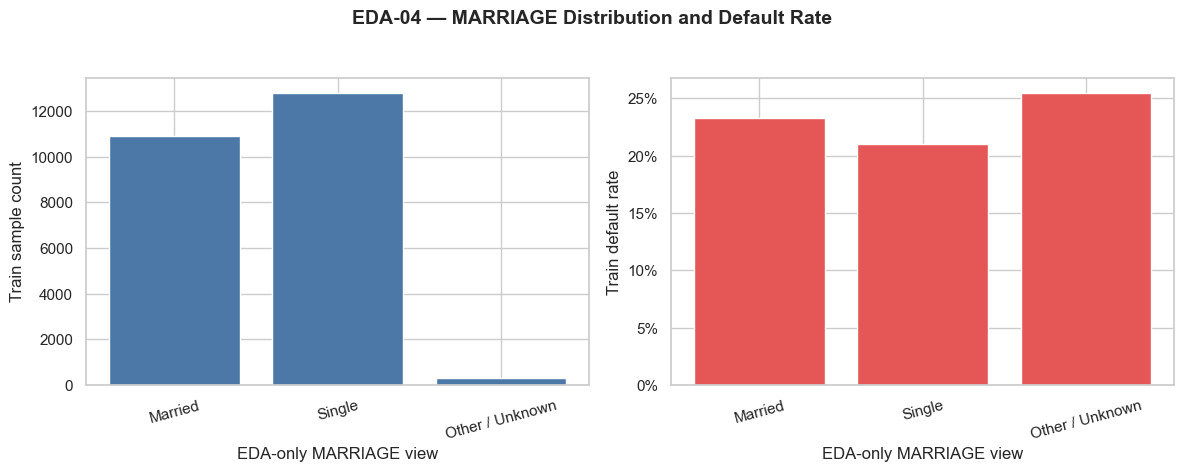

,sample_count,defaults,default_rate
MARRIAGE_VIEW,,,
Married,10892,2538,0.233015
Single,12806,2694,0.210370
Other / Unknown,302,77,0.254967


In [8]:
marriage_stats = analysis_train.groupby("MARRIAGE_VIEW", observed=True)[TARGET].agg(sample_count="size", defaults="sum", default_rate="mean").reindex(MARRIAGE_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].bar(marriage_stats.index, marriage_stats["sample_count"], color="#4C78A8")
axes[0].set_ylabel("Train sample count"); axes[0].set_xlabel("EDA-only MARRIAGE view")
axes[1].bar(marriage_stats.index, marriage_stats["default_rate"], color="#E45756")
axes[1].set_ylabel("Train default rate"); axes[1].set_xlabel("EDA-only MARRIAGE view"); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
for ax in axes: ax.tick_params(axis="x", rotation=15)
finalize_figure(fig, "EDA-04", "MARRIAGE Distribution and Default Rate")
display(marriage_stats)


## EDA-05 — Continuous AGE Distribution by Target

### Question

How does the continuous age distribution compare between Train target classes?

### Why

Overlaid density-normalized histograms retain raw age resolution. The x-axis is age in years; no manual age groups or modeling bins are created.

### Observed finding

The two continuous age distributions overlap strongly: mean age is 35.37 for non-default and 35.65 for default observations, while both medians are 34. Train ages span 21–75 in both classes.

### Stage 3.2 question

Does continuous AGE need a flexible or monotonic treatment later, and how should that be validated without target-driven manual bins?


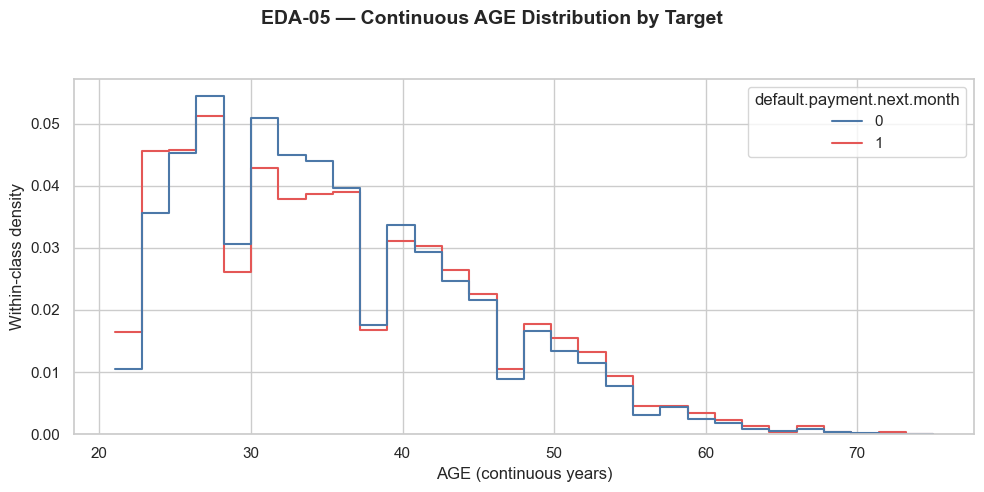

,sample_count,mean,median,std,min,max
Non-default (0),18691,35.369750,34.0,9.046109,21,75
Default (1),5309,35.653984,34.0,9.699764,21,75


In [9]:
age_stats = train_df.groupby(TARGET)["AGE"].agg(sample_count="size", mean="mean", median="median", std="std", min="min", max="max")
age_stats.index = ["Non-default (0)", "Default (1)"]
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=train_df, x="AGE", hue=TARGET, stat="density", common_norm=False, element="step", fill=False, bins=30, ax=ax, palette=["#4C78A8", "#E45756"])
ax.set_xlabel("AGE (continuous years)"); ax.set_ylabel("Within-class density")
finalize_figure(fig, "EDA-05", "Continuous AGE Distribution by Target")
display(age_stats)


## EDA-06 — SEX × MARRIAGE Sample Size

### Question

Are the Train observations across SEX and EDA-grouped MARRIAGE combinations sufficiently represented for interpretation?

### Why

The heatmap cells are Train counts. It checks support before interpreting interaction rates; it does not create an interaction predictor.

### Observed finding

The four Married/Single combinations have 4,154–7,588 observations. Other / Unknown combinations are much smaller (114 Male and 188 Female), so their joint rates require caution.

### Stage 3.2 question

Are all joint groups sufficiently supported to justify testing an interaction concept in Stage 3.2?


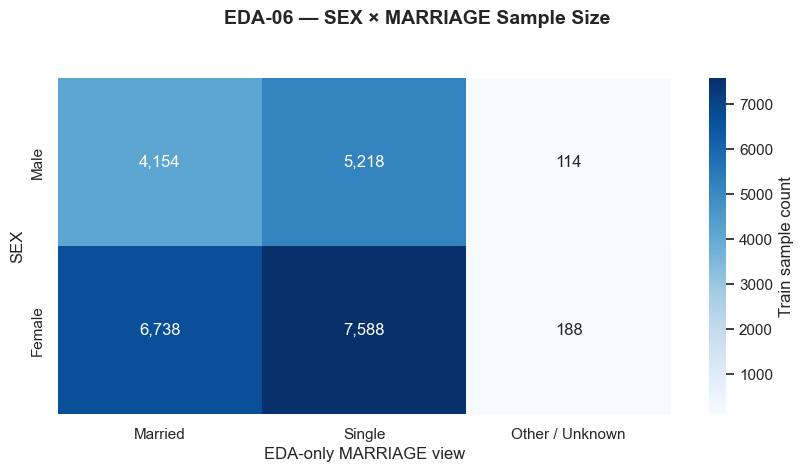

MARRIAGE_VIEW,Married,Single,Other / Unknown
SEX_VIEW,,,
Male,4154,5218,114
Female,6738,7588,188


In [10]:
sex_marriage_counts = pd.crosstab(analysis_train["SEX_VIEW"], analysis_train["MARRIAGE_VIEW"]).reindex(index=SEX_ORDER, columns=MARRIAGE_ORDER)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.heatmap(sex_marriage_counts, annot=True, fmt=",d", cmap="Blues", ax=ax, cbar_kws={"label": "Train sample count"})
ax.set_xlabel("EDA-only MARRIAGE view"); ax.set_ylabel("SEX")
finalize_figure(fig, "EDA-06", "SEX × MARRIAGE Sample Size")
display(sex_marriage_counts)


## EDA-07 — SEX × MARRIAGE Default Rate

### Question

Do the supported SEX × MARRIAGE groups show distinct Train default rates?

### Why

The heatmap reports target mean within each Train-only group. It revisits Luca's interaction idea as evidence only; no SE_MA column is created.

### Observed finding

Male default rates exceed Female rates within Married (25.85% vs 21.73%) and Single (23.04% vs 19.66%) groups. Male × Other / Unknown is highest at 31.58%, but it is based on only 114 observations and is not sufficient to authorize an interaction feature.

### Stage 3.2 question

Do the joint rates add stable information beyond separate variables, and what validation would be required before any interaction is authorized?


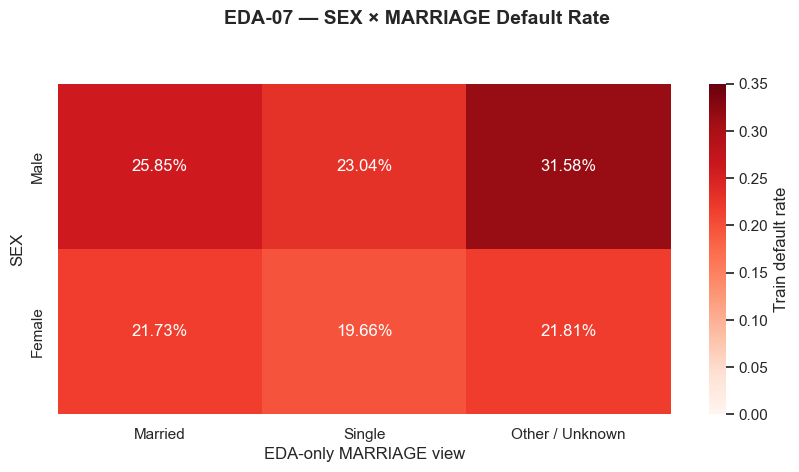

MARRIAGE_VIEW,Married,Single,Other / Unknown
SEX_VIEW,,,
Male,0.258546,0.230356,0.315789
Female,0.217275,0.196626,0.218085


In [11]:
sex_marriage_rates = analysis_train.pivot_table(index="SEX_VIEW", columns="MARRIAGE_VIEW", values=TARGET, aggfunc="mean", observed=True).reindex(index=SEX_ORDER, columns=MARRIAGE_ORDER)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.heatmap(sex_marriage_rates, annot=True, fmt=".2%", cmap="Reds", vmin=0, vmax=max(0.35, float(np.nanmax(sex_marriage_rates))), ax=ax, cbar_kws={"label": "Train default rate"})
ax.set_xlabel("EDA-only MARRIAGE view"); ax.set_ylabel("SEX")
finalize_figure(fig, "EDA-07", "SEX × MARRIAGE Default Rate")
display(sex_marriage_rates)


## EDA-08 — LIMIT_BAL Distribution and Target Relationship

### Question

How is credit limit distributed in Train, and how do the two target groups differ in their unbinned distributions?

### Why

The density panel keeps LIMIT_BAL continuous; the boxplot summarizes class distributions. No observations are removed and no credit-limit bins are created.

### Observed finding

Non-default observations have mean/median LIMIT_BAL of 178,477/150,000, compared with 128,243/90,000 for defaults. The distributions still overlap, so this is descriptive separation rather than a modeling rule.

### Stage 3.2 question

Should later design keep LIMIT_BAL continuous, transform it, or combine it with other fields only after leakage-safe validation?


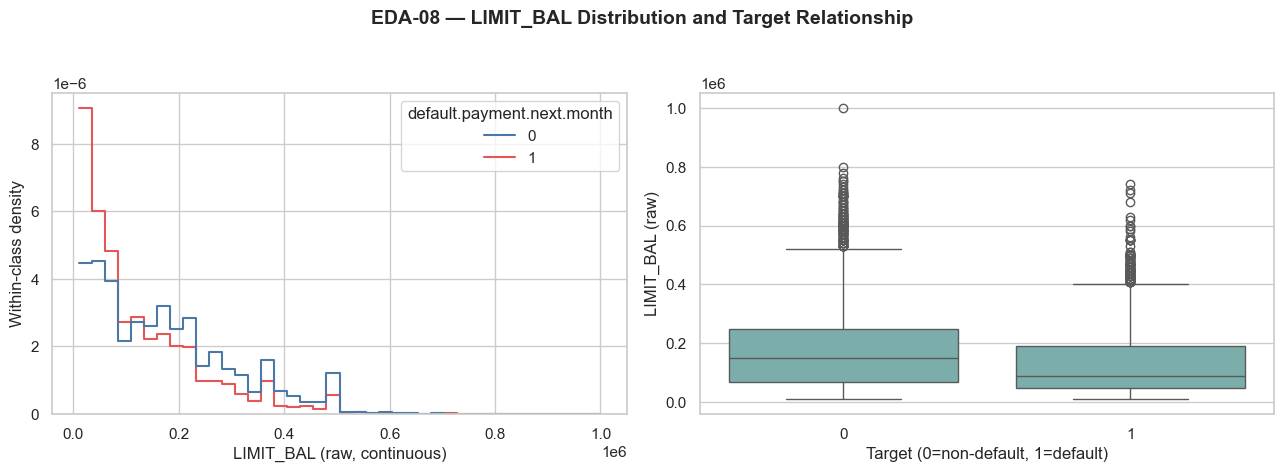

,sample_count,mean,median,std,min,max
Non-default (0),18691,178476.914023,150000.0,131448.983850,10000.0,1000000.0
Default (1),5309,128242.606894,90000.0,114150.068073,10000.0,740000.0


In [12]:
limit_stats = train_df.groupby(TARGET)["LIMIT_BAL"].agg(sample_count="size", mean="mean", median="median", std="std", min="min", max="max")
limit_stats.index = ["Non-default (0)", "Default (1)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(data=train_df, x="LIMIT_BAL", hue=TARGET, stat="density", common_norm=False, element="step", fill=False, bins=40, ax=axes[0], palette=["#4C78A8", "#E45756"])
axes[0].set_xlabel("LIMIT_BAL (raw, continuous)"); axes[0].set_ylabel("Within-class density")
sns.boxplot(data=train_df, x=TARGET, y="LIMIT_BAL", ax=axes[1], color="#72B7B2")
axes[1].set_xlabel("Target (0=non-default, 1=default)"); axes[1].set_ylabel("LIMIT_BAL (raw)")
finalize_figure(fig, "EDA-08", "LIMIT_BAL Distribution and Target Relationship")
display(limit_stats)


## EDA-09 — PAY Raw Code Frequency by Month

### Question

Are raw repayment-status codes systematic across months, and which codes are common or rare?

### Why

Rows follow the six-month chronology from PAY_6 to PAY_0; columns are untouched raw codes. Cell labels are Train counts, while color uses log(1+count) only to make large and small frequencies visible.

### Observed finding

Codes -2, -1, and 0 occur in every month at substantial frequency. Code 2 also occurs in every month (2,102–3,145 rows); codes 7 and 8 are rare, and code 1 is absent in PAY_5/PAY_6, nearly absent in PAY_2–PAY_4, but appears 3,000 times in PAY_0. The special codes are systematic rather than isolated dirty values.

### Stage 3.2 question

Which raw codes should remain distinct or require an explicitly documented grouping proposal in Stage 3.2?


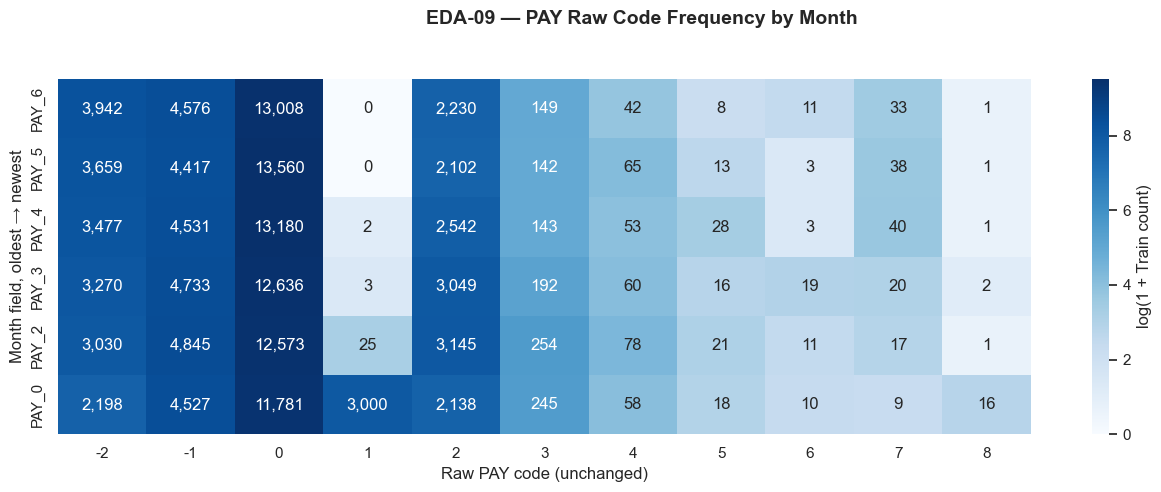

,-2,-1,0,1,2,3,4,5,6,7,8
PAY_6,3942,4576,13008,0,2230,149,42,8,11,33,1
PAY_5,3659,4417,13560,0,2102,142,65,13,3,38,1
PAY_4,3477,4531,13180,2,2542,143,53,28,3,40,1
PAY_3,3270,4733,12636,3,3049,192,60,16,19,20,2
PAY_2,3030,4845,12573,25,3145,254,78,21,11,17,1
PAY_0,2198,4527,11781,3000,2138,245,58,18,10,9,16


In [13]:
all_pay_codes = sorted(set().union(*(set(train_df[col].unique()) for col in PAY_CHRONO)))
pay_code_counts = pd.DataFrame({col: train_df[col].value_counts() for col in PAY_CHRONO}).T.reindex(index=PAY_CHRONO, columns=all_pay_codes).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(np.log1p(pay_code_counts), annot=pay_code_counts, fmt=",d", cmap="Blues", ax=ax, cbar_kws={"label": "log(1 + Train count)"})
ax.set_xlabel("Raw PAY code (unchanged)"); ax.set_ylabel("Month field, oldest → newest")
finalize_figure(fig, "EDA-09", "PAY Raw Code Frequency by Month")
display(pay_code_counts)


## EDA-10 — PAY Raw Code Default Rate by Month

### Question

How does Train default rate vary across each raw PAY code and month?

### Why

Rows are months and columns are unchanged raw codes; annotations show Train default rates. Blank cells mean that code is absent in that month. This examines risk ordering without binary compression.

### Observed finding

Across months, raw code 2 has observed default rates of 50.67%–69.36% and code 3 has 57.81%–76.73%, while non-positive codes are mostly 12.69%–19.74%. Very high codes often show high rates, but their tiny counts make individual estimates unstable; PAY_2 code 8, for example, appears once and has a 0% observed rate.

### Stage 3.2 question

Should Stage 3.2 test raw severity, carefully justified groupings, or parallel representations while preserving month timing?


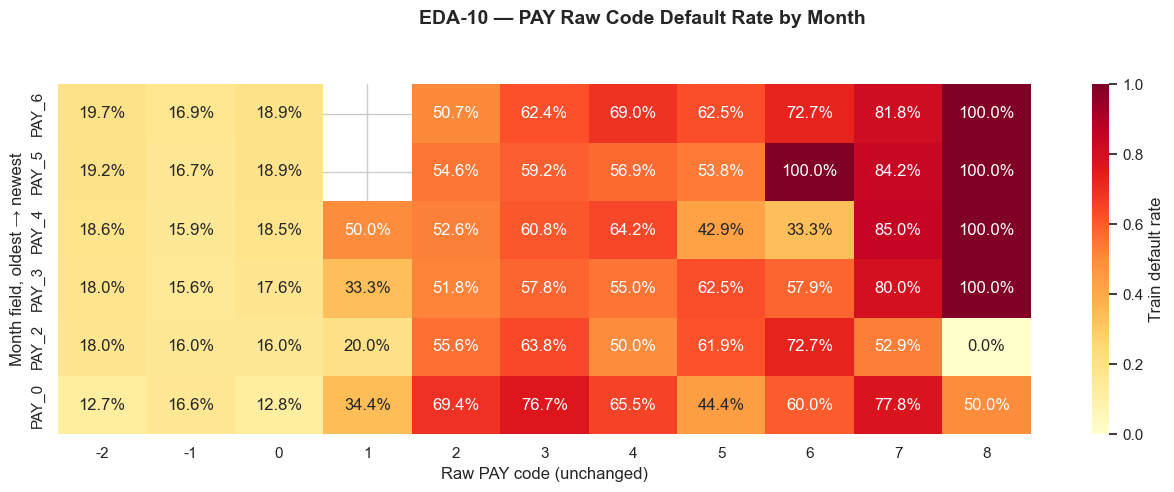

,-2,-1,0,1,2,3,4,5,6,7,8
PAY_6,0.197362,0.168925,0.189499,NaN,0.506726,0.624161,0.690476,0.625000,0.727273,0.818182,1.0
PAY_5,0.191582,0.166629,0.188791,NaN,0.546147,0.591549,0.569231,0.538462,1.000000,0.842105,1.0
PAY_4,0.185792,0.159347,0.184598,0.500000,0.526357,0.608392,0.641509,0.428571,0.333333,0.850000,1.0
PAY_3,0.180122,0.155504,0.175689,0.333333,0.518203,0.578125,0.550000,0.625000,0.578947,0.800000,1.0
PAY_2,0.179538,0.159752,0.159548,0.200000,0.556121,0.637795,0.500000,0.619048,0.727273,0.529412,0.0
PAY_0,0.126934,0.166335,0.128003,0.343667,0.693639,0.767347,0.655172,0.444444,0.600000,0.777778,0.5


In [14]:
pay_default_rates = pd.DataFrame(index=PAY_CHRONO, columns=all_pay_codes, dtype=float)
for col in PAY_CHRONO:
    pay_default_rates.loc[col] = train_df.groupby(col)[TARGET].mean().reindex(all_pay_codes)
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pay_default_rates.astype(float), annot=True, fmt=".1%", cmap="YlOrRd", mask=pay_default_rates.isna(), vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Train default rate"})
ax.set_xlabel("Raw PAY code (unchanged)"); ax.set_ylabel("Month field, oldest → newest")
finalize_figure(fig, "EDA-10", "PAY Raw Code Default Rate by Month")
display(pay_default_rates)


## EDA-11 — PAY Adjacent-Month Transition Patterns

### Question

What transitions occur across all five adjacent month pairs, and what repayment trajectories dominate Train?

### Why

Each panel is a complete older→newer raw-code transition matrix. Color uses log(1+count) for legibility. Supporting tables retain most-common transitions, objectively large code jumps, and top six-month raw trajectories.

### Observed finding

Train contains 1,023 distinct six-month raw trajectories. Persistence dominates: 0→0→0→0→0→0 is 7,853 rows (32.7208%), followed by constant -2 (1,689) and constant -1 (1,563). For every adjacent pair, same-code 0→0 is most common (11,258–11,871 rows); absolute raw-code jumps of at least 5 are rare, with the largest listed pattern occurring only 20 times.

### Stage 3.2 question

Should Stage 3.2 represent persistence, direction, severity, or trajectory information, and how can that be done without imposing unverified business meanings?


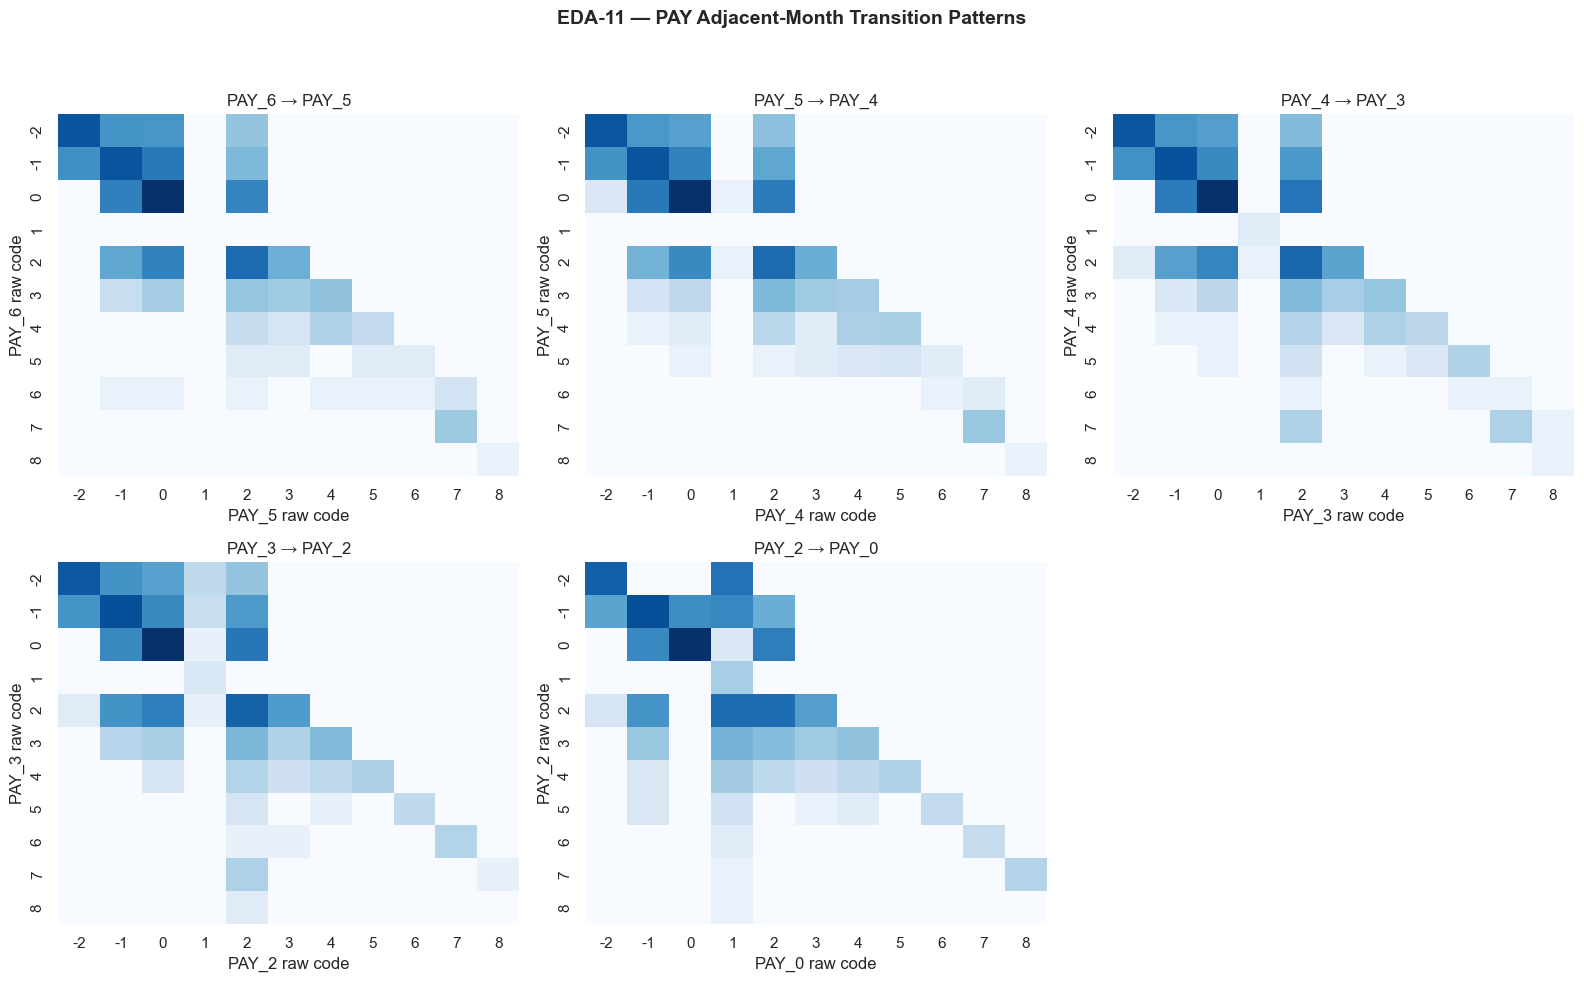

Most common transitions (top 5 per adjacent pair):


,from_code,to_code,count,transition
0,0,0,11397,PAY_2 → PAY_0
1,-1,-1,3686,PAY_2 → PAY_0
2,-2,-2,2035,PAY_2 → PAY_0
3,2,1,1349,PAY_2 → PAY_0
4,2,2,1269,PAY_2 → PAY_0
5,0,0,11258,PAY_3 → PAY_2
6,-1,-1,3717,PAY_3 → PAY_2
7,-2,-2,2715,PAY_3 → PAY_2
8,2,2,1830,PAY_3 → PAY_2
9,0,2,907,PAY_3 → PAY_2


Observed large raw-code jumps (absolute change >=5), ranked by Train count; no business meaning is assigned:


,from_code,to_code,count,transition
0,7,2,20,PAY_4 → PAY_3
1,7,2,19,PAY_3 → PAY_2
2,4,-1,3,PAY_2 → PAY_0
3,5,-1,3,PAY_2 → PAY_0
4,8,2,2,PAY_3 → PAY_2
5,6,1,2,PAY_2 → PAY_0
6,6,-1,1,PAY_6 → PAY_5
7,6,0,1,PAY_6 → PAY_5
8,4,-1,1,PAY_5 → PAY_4
9,5,0,1,PAY_5 → PAY_4


Distinct six-month raw trajectories in Train: 1023
Top raw trajectories:


,count,proportion
0 → 0 → 0 → 0 → 0 → 0,7853,0.327208
-2 → -2 → -2 → -2 → -2 → -2,1689,0.070375
-1 → -1 → -1 → -1 → -1 → -1,1563,0.065125
-2 → -2 → -2 → -2 → -2 → 1,527,0.021958
2 → 2 → 2 → 2 → 2 → 2,415,0.017292
0 → 0 → 0 → 0 → 0 → 2,410,0.017083
0 → 0 → 0 → 0 → 2 → 1,395,0.016458
2 → 0 → 0 → 0 → 0 → 0,293,0.012208
0 → 0 → 0 → 2 → 0 → 0,293,0.012208
-1 → 0 → 0 → 0 → 0 → 0,266,0.011083


In [15]:
transition_pairs = list(zip(PAY_CHRONO[:-1], PAY_CHRONO[1:]))
transition_matrices = {}
transition_rows = []
for older, newer in transition_pairs:
    matrix = pd.crosstab(train_df[older], train_df[newer]).reindex(index=all_pay_codes, columns=all_pay_codes, fill_value=0)
    transition_matrices[(older, newer)] = matrix
    stacked = matrix.stack().rename("count").reset_index()
    stacked.columns = ["from_code", "to_code", "count"]
    stacked["transition"] = f"{older} → {newer}"
    transition_rows.append(stacked[stacked["count"] > 0])
transition_long = pd.concat(transition_rows, ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, ((older, newer), matrix) in zip(axes.flat, transition_matrices.items()):
    sns.heatmap(np.log1p(matrix), cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{older} → {newer}")
    ax.set_xlabel(f"{newer} raw code"); ax.set_ylabel(f"{older} raw code")
axes.flat[-1].axis("off")
finalize_figure(fig, "EDA-11", "PAY Adjacent-Month Transition Patterns")

most_common_transitions = (transition_long.sort_values(["transition", "count"], ascending=[True, False]).groupby("transition", sort=False).head(5).reset_index(drop=True))
large_jump_transitions = transition_long.loc[(transition_long["from_code"] - transition_long["to_code"]).abs() >= 5].sort_values("count", ascending=False).head(15).reset_index(drop=True)
trajectory_text = train_df[PAY_CHRONO].astype(str).agg(" → ".join, axis=1)
trajectory_summary = trajectory_text.value_counts().rename("count").to_frame()
trajectory_summary["proportion"] = trajectory_summary["count"] / len(train_df)
distinct_trajectory_count = int(trajectory_text.nunique())

print("Most common transitions (top 5 per adjacent pair):")
display(most_common_transitions)
print("Observed large raw-code jumps (absolute change >=5), ranked by Train count; no business meaning is assigned:")
display(large_jump_transitions)
print("Distinct six-month raw trajectories in Train:", distinct_trajectory_count)
print("Top raw trajectories:")
display(trajectory_summary.head(15))


## EDA-12 — BILL_AMT Monthly Distribution

### Question

What do the six raw bill-amount distributions look like, including zeros, negatives, and extreme tails?

### Why

The left boxplot limits the visible y-axis to pooled Train 1st–99th percentiles for central readability; the right uses a symmetric-log y-axis to retain full tails including negatives. These are display choices only: no row is dropped, clipped, or winsorized.

### Observed finding

Every BILL_AMT month contains zeros (1,612–3,223) and negatives (468–556). Monthly p99 values range from about 274,503 to 348,402, while maxima reach 855,086–983,931; the large gap confirms long tails. No value or row was altered.

### Stage 3.2 question

What robust treatment, if any, should Stage 3.2 consider while preserving legitimate negative balances and extreme values?


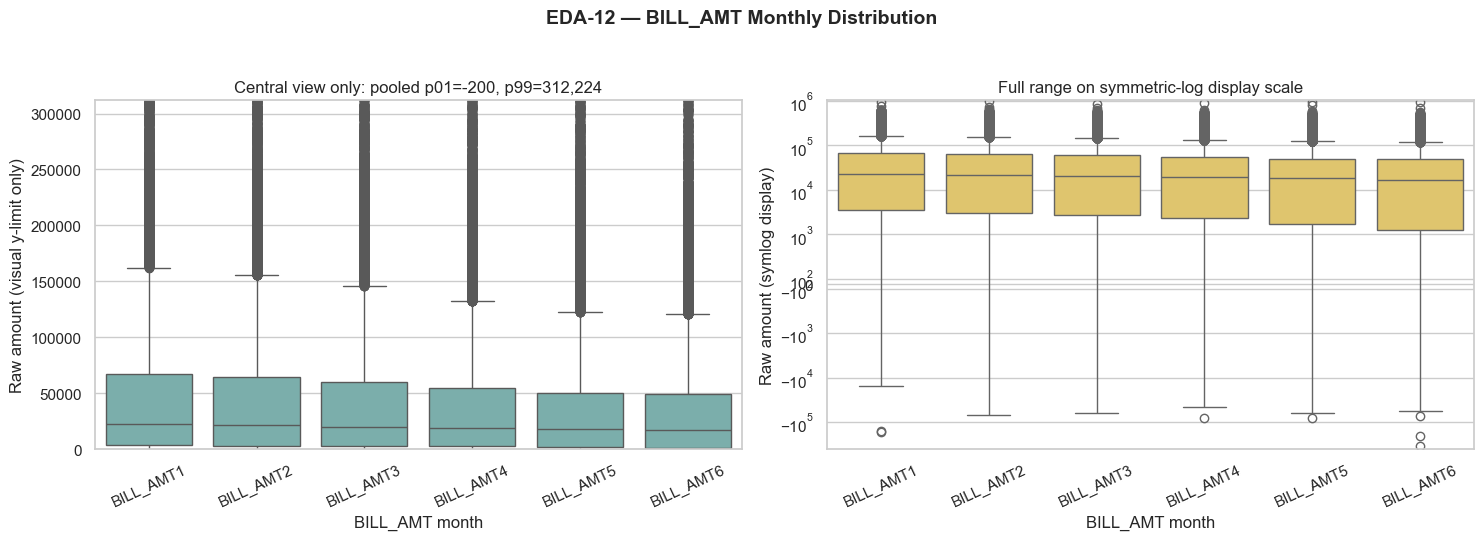

Visualization bounds only; raw values and all observations remain unchanged.


,min,p01,p25,median,p75,p99,max,zero_count,negative_count
BILL_AMT1,-165580.0,-77.01,3513.75,22330.0,66966.50,348402.41,964511.0,1612,468
BILL_AMT2,-69777.0,-152.06,2989.75,21107.0,63992.75,334929.25,983931.0,1986,522
BILL_AMT3,-61506.0,-180.05,2652.00,20031.0,60033.75,323101.81,855086.0,2308,515
BILL_AMT4,-81334.0,-201.01,2332.00,19004.5,54386.50,304594.51,891586.0,2555,530
BILL_AMT5,-81334.0,-217.03,1746.00,18102.5,50142.25,284834.81,927171.0,2828,524
BILL_AMT6,-339603.0,-311.09,1225.00,16993.0,48977.25,274502.88,961664.0,3223,556


In [16]:
bill_long = train_df[BILL_COLS].melt(var_name="month", value_name="raw_bill_amount")
bill_display_low = float(bill_long["raw_bill_amount"].quantile(0.01))
bill_display_high = float(bill_long["raw_bill_amount"].quantile(0.99))
bill_stats = pd.DataFrame({
    "min": train_df[BILL_COLS].min(), "p01": train_df[BILL_COLS].quantile(0.01),
    "p25": train_df[BILL_COLS].quantile(0.25), "median": train_df[BILL_COLS].median(),
    "p75": train_df[BILL_COLS].quantile(0.75), "p99": train_df[BILL_COLS].quantile(0.99),
    "max": train_df[BILL_COLS].max(), "zero_count": (train_df[BILL_COLS] == 0).sum(),
    "negative_count": (train_df[BILL_COLS] < 0).sum(),
})
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=bill_long, x="month", y="raw_bill_amount", ax=axes[0], color="#72B7B2")
axes[0].set_ylim(bill_display_low, bill_display_high)
axes[0].set_title(f"Central view only: pooled p01={bill_display_low:,.0f}, p99={bill_display_high:,.0f}")
axes[0].set_xlabel("BILL_AMT month"); axes[0].set_ylabel("Raw amount (visual y-limit only)")
sns.boxplot(data=bill_long, x="month", y="raw_bill_amount", ax=axes[1], color="#F2CF5B")
axes[1].set_yscale("symlog", linthresh=1000)
axes[1].set_title("Full range on symmetric-log display scale")
axes[1].set_xlabel("BILL_AMT month"); axes[1].set_ylabel("Raw amount (symlog display)")
for ax in axes: ax.tick_params(axis="x", rotation=25)
finalize_figure(fig, "EDA-12", "BILL_AMT Monthly Distribution")
print("Visualization bounds only; raw values and all observations remain unchanged.")
display(bill_stats)


## EDA-13 — PAY_AMT Monthly Distribution

### Question

What do the six raw payment-amount distributions look like, including zeros and extreme tails?

### Why

The left boxplot limits the visible y-axis to the pooled Train 99th percentile. The right overlays log1p-scaled histograms to display zero-heavy right tails. log1p is used only as a plotting coordinate, not as a saved transformation or predictor.

### Observed finding

PAY_AMT fields have no negative values but contain 4,180–5,787 zeros. Monthly medians are 1,500–2,100.5, p99 values are about 64,578–83,026, and maxima range from 426,529 to 1,215,471, confirming zero-heavy, strongly right-tailed distributions.

### Stage 3.2 question

Should Stage 3.2 evaluate a robust scale or ratio concept, and what business/temporal checks are required before doing so?


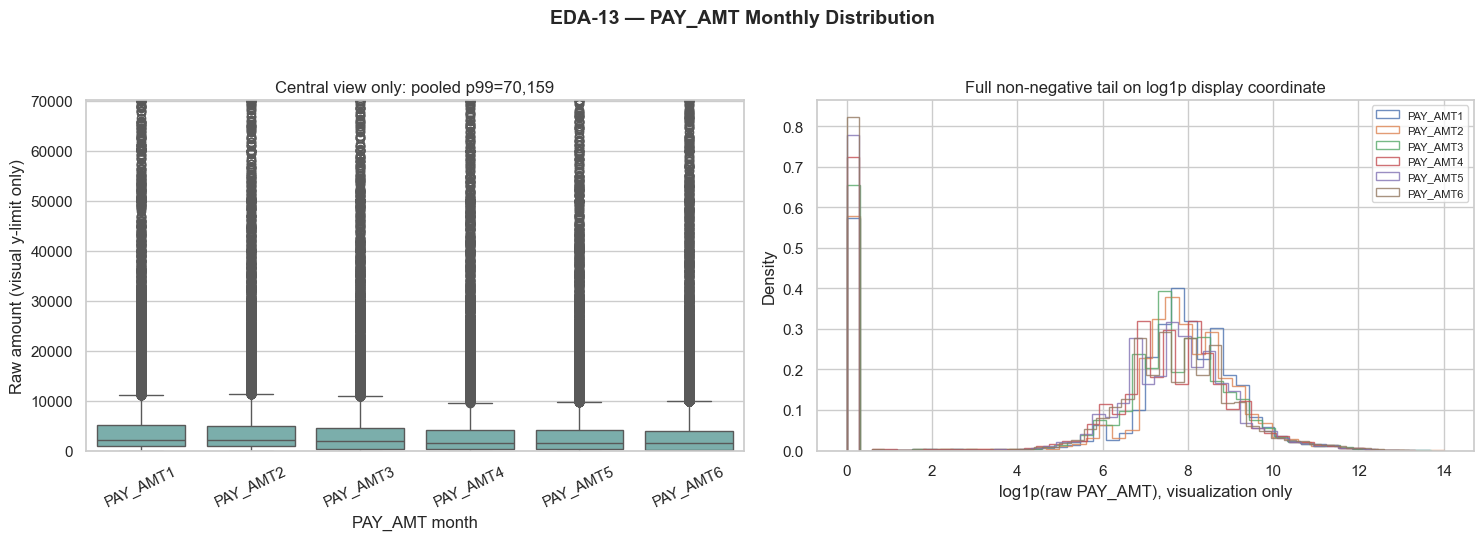

Percentile limit and log1p are visualization-only; no raw value or observation was changed.


,min,p01,p25,median,p75,p99,max,zero_count,negative_count
PAY_AMT1,0.0,0.0,1000.0,2100.5,5018.25,67572.32,873552.0,4180,0
PAY_AMT2,0.0,0.0,840.0,2014.0,5000.00,77010.79,1215471.0,4324,0
PAY_AMT3,0.0,0.0,390.0,1805.5,4580.50,70077.15,896040.0,4780,0
PAY_AMT4,0.0,0.0,291.0,1500.0,4015.25,64760.42,621000.0,5141,0
PAY_AMT5,0.0,0.0,246.0,1500.0,4040.00,64578.20,426529.0,5387,0
PAY_AMT6,0.0,0.0,100.0,1500.0,4000.00,83025.53,528666.0,5787,0


In [17]:
pay_amt_long = train_df[PAY_AMT_COLS].melt(var_name="month", value_name="raw_payment_amount")
pay_display_high = float(pay_amt_long["raw_payment_amount"].quantile(0.99))
pay_amt_stats = pd.DataFrame({
    "min": train_df[PAY_AMT_COLS].min(), "p01": train_df[PAY_AMT_COLS].quantile(0.01),
    "p25": train_df[PAY_AMT_COLS].quantile(0.25), "median": train_df[PAY_AMT_COLS].median(),
    "p75": train_df[PAY_AMT_COLS].quantile(0.75), "p99": train_df[PAY_AMT_COLS].quantile(0.99),
    "max": train_df[PAY_AMT_COLS].max(), "zero_count": (train_df[PAY_AMT_COLS] == 0).sum(),
    "negative_count": (train_df[PAY_AMT_COLS] < 0).sum(),
})
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=pay_amt_long, x="month", y="raw_payment_amount", ax=axes[0], color="#72B7B2")
axes[0].set_ylim(0, pay_display_high)
axes[0].set_title(f"Central view only: pooled p99={pay_display_high:,.0f}")
axes[0].set_xlabel("PAY_AMT month"); axes[0].set_ylabel("Raw amount (visual y-limit only)")
for col in PAY_AMT_COLS:
    axes[1].hist(np.log1p(train_df[col]), bins=45, histtype="step", density=True, label=col, alpha=0.8)
axes[1].set_title("Full non-negative tail on log1p display coordinate")
axes[1].set_xlabel("log1p(raw PAY_AMT), visualization only"); axes[1].set_ylabel("Density")
axes[1].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=25)
finalize_figure(fig, "EDA-13", "PAY_AMT Monthly Distribution")
print("Percentile limit and log1p are visualization-only; no raw value or observation was changed.")
display(pay_amt_stats)


## 4. Observed findings summary

- The stratified Train sample retains a 22.1208% default rate; Test remains sealed and was not profiled by target.
- Demographic group rates differ descriptively, but pooled unknown groups and some interactions have limited support.
- AGE class distributions overlap, while LIMIT_BAL is lower on average and at the median among Train defaults.
- Raw PAY codes show systematic monthly presence, distinct risk levels, strong persistence, and 1,023 Train trajectories; rare severe codes require sample-size caution.
- BILL_AMT includes zeros, negatives, and long tails; PAY_AMT is non-negative, zero-heavy, and strongly right-tailed.
- These are Train-only facts and questions, not final feature decisions.

## 5. Stage 3.2 open questions

The formal figures intentionally leave design choices open for Architect + user review. Topics include transparent treatment of undocumented categories, continuous variable scale, repayment severity/timing/trajectory, interaction stability, and robust handling of legitimate extremes. No candidate concept is authorized or implemented here.

## 6. Scope confirmation

The next code cell verifies figure completeness and the central scope constraints. Stage 3.1 stops after this checkpoint.


In [18]:
assert figure_registry == EXPECTED_FIGURE_IDS
assert analysis_train["AGE"].equals(train_df["AGE"])
assert analysis_train[PAY_SOURCE_ORDER].equals(train_df[PAY_SOURCE_ORDER])
assert set(analysis_train.columns) - set(train_df.columns) == {"SEX_VIEW", "EDUCATION_VIEW", "MARRIAGE_VIEW"}
assert TEST_ISOLATION_STATUS.startswith("sealed")

scope_confirmation = pd.DataFrame({
    "status": [
        "PASS — all target-aware EDA uses Train",
        "PASS — sealed Test frame was deleted before EDA",
        "PASS — AGE remains continuous; no AgeBin",
        "PASS — PAY raw values unchanged; no binary mapping",
        "PASS — no SE_MA or other formal predictor created",
        "PASS — no WOE, sampling, model, CV, GridSearch, threshold, or evaluation",
        "PASS — no processed or split dataset written",
        "PASS — Post-EDA Human Checkpoint reached",
    ]
}, index=[
    "train_only_target_aware_EDA", "test_isolation", "age_scope", "PAY_scope",
    "feature_engineering_scope", "modeling_scope", "data_write_scope", "stop_condition",
])
print("Formal figure registry:", figure_registry)
display(scope_confirmation)


Formal figure registry: ['EDA-01', 'EDA-02', 'EDA-03', 'EDA-04', 'EDA-05', 'EDA-06', 'EDA-07', 'EDA-08', 'EDA-09', 'EDA-10', 'EDA-11', 'EDA-12', 'EDA-13']


,status
train_only_target_aware_EDA,PASS — all target-aware EDA uses Train
test_isolation,PASS — sealed Test frame was deleted before EDA
age_scope,PASS — AGE remains continuous; no AgeBin
PAY_scope,PASS — PAY raw values unchanged; no binary map...
feature_engineering_scope,PASS — no SE_MA or other formal predictor created
modeling_scope,"PASS — no WOE, sampling, model, CV, GridSearch..."
data_write_scope,PASS — no processed or split dataset written
stop_condition,PASS — Post-EDA Human Checkpoint reached
